<h1>Newton's Method</h1>

$m_{tangent} = f'(x_0)$

$y-f(x_0) = f'(x_0) \cdot (x-x_0)$

$0 - f(x_0)= f'(x_0) \cdot (x-x_0) $

$x_1 = x_0 - \frac{f(x_0)}{f'(x_0)}$

$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$

[1.414213562373095, -4.440892098500626e-16]
[3, 1.8333333333333333, 1.4621212121212122, 1.4149984298948028, 1.4142137800471977, 1.4142135623731118]


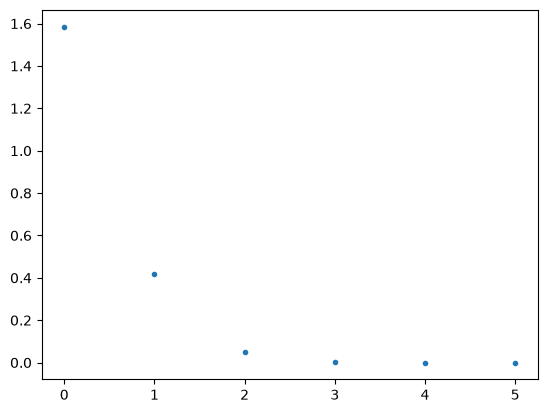

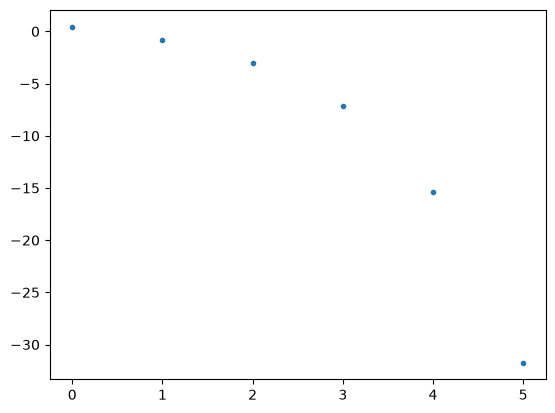

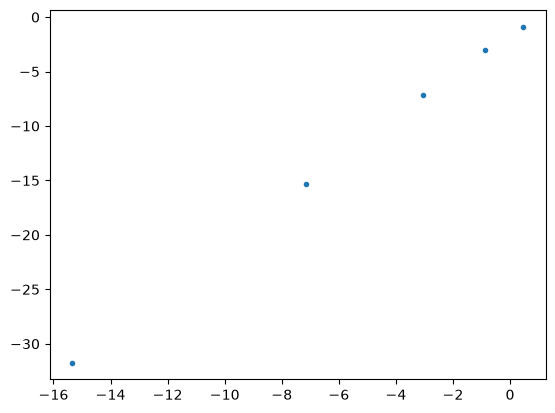

In [1]:
import numpy as np  

def newton(f, df, x0, tol):
    """
    f : The function for approximating the root.
    df :The derivative of the function f.
    x0 :The initial guess.
    tol :The tolerance for convergence.
    """
    # Initialize the approximation
    x = x0
    approx = []
    
    while True:
        
        # Calculate the value of the function and its derivative at the current approximation
        fx = f(x)
        dfx = df(x)
        
        # Check if the derivative is too small which might cause division by zero
        if dfx == 0 or np.abs(dfx) < tol:
            raise ValueError("Derivative is almost 0; fail to converge.")
        
        # Update the current approximation
        x_new = x - fx / dfx

        approx.append(x)
        
        # Check if the update is smaller than our tolerance, which is converged to the root.
        if abs(x_new - x) < tol:
            return x_new, approx
        
        # Update the current approximation
        x = x_new
        


def f(x):
    return x**2 - 2

def df(x):
    return 2*x

import matplotlib.pyplot as plt 

a,iterates = newton(f,df,3,1e-8)
print([a,f(a)])
print(iterates)

errors = np.abs(iterates - np.sqrt(2))
plt.figure()
plt.plot(range(len(iterates)),errors,'.')

plt.figure()
plt.plot(range(len(iterates)),np.log(errors),'.')

plt.figure()
plt.plot(np.log(errors[0:-1]),np.log(errors[1:]),'.')

[1.4142135623731118, 4.75175454539567e-14]
[3, 1.8333333333333333, 1.4621212121212122, 1.4149984298948028, 1.4142137800471977, 1.4142135623731118]


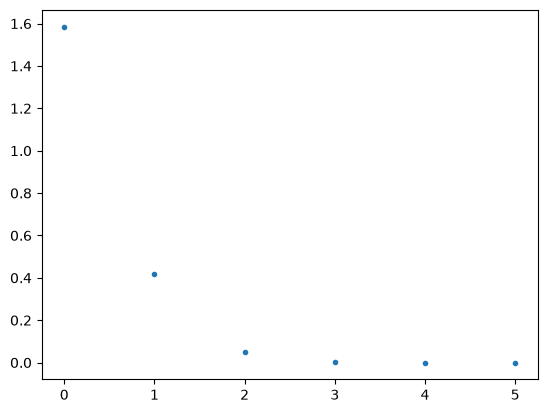

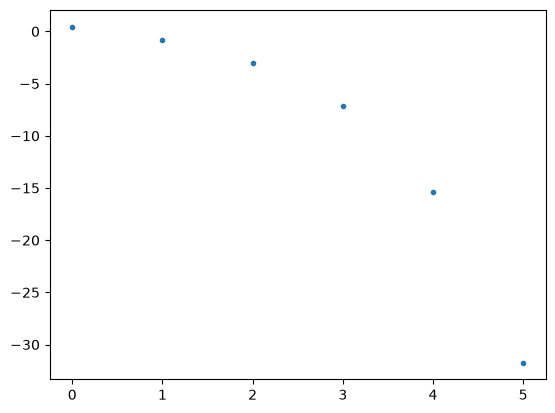

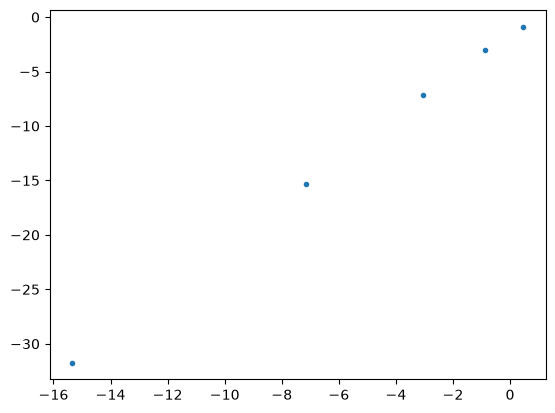

In [2]:
def Newton(f, df, x, tol):
    error = f(x)
    approx = [x]
    
    while np.abs(error)> tol:
        x = x - f(x)/df(x)
        
        error = f(x)
        approx.append(x)
        
    return x, approx



def f(x):
    return x**2-2

def df(x):
    return 2*x

a,iterates = Newton(f,df,3,1e-8)
print([a,f(a)])
print(iterates)

errors = np.abs(iterates - np.sqrt(2))
plt.figure()
plt.plot(range(len(iterates)),errors,'.')

plt.figure()
plt.plot(range(len(iterates)),np.log(errors),'.')

plt.figure()
plt.plot(np.log(errors[0:-1]),np.log(errors[1:]),'.')

<h1>Secant Method</h1>

In [3]:
def secant(f, x0, x1, tol):
    """
    f : function
    x0, x1 : The initial two guesses for the root.
    tol : The tolerance for convergence
    """
    
    while True:
    # function values for the selected xs
        f_x0 = f(x0)
        f_x1 = f(x1)
    
    # check that the initial difference is large enough
        if np.abs(f_x1 - f_x0) < tol:
            raise Exception("Difference between points is too small.")
    
        x_new = x1 - (f(x1)*(x1 - x0))/(f(x1) - f(x0)) # Update
        
        if np.abs(x_new - x1) < tol:
            return x_new
        
        x0, x1 = x1, x_new
        
def f(x):
    return x**2 - 2

root_1 = secant(f, 1, 1.2, 1e-10)
root_2 = secant(f, -1, -2, 1e-10)
root_1, root_2
    
    

(1.414213562373095, -1.4142135623730951)